# Taller: Evaluación de modelos y ajuste de hiperparámetros

**Machine Learning – Universidad Libre**
Rebeca Pedrozo Cueto

---

### Contenido

| Paso | Tema |
|---|---|
| 1 | Cargar datos y dividir en entrenamiento y prueba |
| 2 | Medir MAE, RMSE y R² en entrenamiento vs. prueba |
| 3 | Detectar el sobreajuste: polinomios de grado 1 a 15 |
| 4 | Validación cruzada: comparar 3 modelos |
| 5 | `GridSearchCV` y `RandomizedSearchCV` |
| 6 | Clasificación: matriz de confusión, F1 y AUC |

Se usan datasets incluidos en scikit-learn, así que **no hay que subir archivos**.
Solo ejecuta las celdas en orden.

## Paso 0 – Preparación

Importamos todo lo necesario y fijamos una semilla para que los resultados sean reproducibles.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes, load_breast_cancer
from sklearn.model_selection import (train_test_split, cross_val_score,
                                     KFold, GridSearchCV, RandomizedSearchCV)
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, f1_score,
                             roc_auc_score, RocCurveDisplay)

SEED = 42
np.random.seed(SEED)
plt.rcParams['figure.figsize'] = (6, 4)
print('Listo ✅')

Listo ✅


## Paso 1 – Cargar datos y dividir en entrenamiento y prueba

Usamos el dataset **diabetes** (regresión): 10 variables clínicas y, como objetivo,
un índice de progresión de la enfermedad.

División **80 % entrenamiento / 20 % prueba**. El conjunto de prueba se guarda y
**no se toca** hasta el final.

In [2]:
X, y = load_diabetes(return_X_y=True, as_frame=True)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED)

print(f'Variables: {list(X.columns)}')
print(f'Entrenamiento: {X_train.shape[0]} filas | Prueba: {X_test.shape[0]} filas')
X.head()

Variables: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
Entrenamiento: 353 filas | Prueba: 89 filas


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


## Paso 2 – Medir MAE, RMSE y R² en entrenamiento vs. prueba

Tres métricas de regresión:

- **MAE**: error promedio en las mismas unidades que `y`. Fácil de interpretar.
- **RMSE**: parecido, pero castiga más los errores grandes.
- **R²**: proporción de la varianza explicada (1 = perfecto, 0 = tan bueno como predecir la media).

Comparamos los valores en entrenamiento y prueba: si en prueba son mucho peores,
hay **sobreajuste**.

In [3]:
def metricas(modelo, X, y):
    pred = modelo.predict(X)
    return {
        'MAE':  mean_absolute_error(y, pred),
        'RMSE': np.sqrt(mean_squared_error(y, pred)),
        'R2':   r2_score(y, pred),
    }

lr = LinearRegression().fit(X_train, y_train)

tabla = pd.DataFrame({
    'entrenamiento': metricas(lr, X_train, y_train),
    'prueba':        metricas(lr, X_test,  y_test),
}).round(3)
tabla

,entrenamiento,prueba
MAE,43.484,42.794
RMSE,53.559,53.853
R2,0.528,0.453


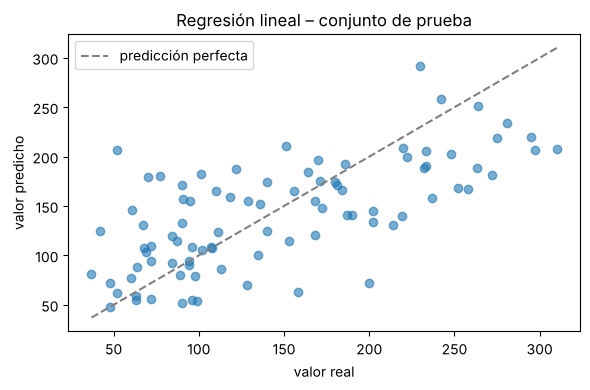

In [4]:
# Predicho vs. real en el conjunto de prueba
pred_test = lr.predict(X_test)

plt.scatter(y_test, pred_test, alpha=0.6)
lims = [y_test.min(), y_test.max()]
plt.plot(lims, lims, '--', color='gray', label='predicción perfecta')
plt.xlabel('valor real'); plt.ylabel('valor predicho')
plt.title('Regresión lineal – conjunto de prueba')
plt.legend(); plt.tight_layout(); plt.show()

**Lectura.** Los valores de entrenamiento y prueba son muy parecidos, así que el
modelo lineal **no está sobreajustado**. Pero el R² ronda 0.5: el modelo es
*demasiado simple* para los datos (**subajuste**). En el gráfico se ve que las
predicciones siguen la tendencia, aunque con bastante dispersión.

## Paso 3 – Detectar el sobreajuste: polinomios de grado 1 a 15

Para que el sobreajuste se vea con claridad usamos **una sola variable** (`bmi`, el
índice de masa corporal) y una **muestra reducida** de entrenamiento. Luego ajustamos
polinomios de grado 1 hasta 15 y medimos el RMSE en entrenamiento y en prueba.

La idea: al subir el grado el modelo se vuelve más flexible, el error de
entrenamiento baja siempre, pero el de prueba primero baja y después **sube**.

> El `MinMaxScaler` antes de `PolynomialFeatures` evita que las potencias altas se
> vuelvan números diminutos y rompan el cálculo.

In [5]:
# Una variable y una muestra reducida -> el efecto se ve mejor
Xb_train = X_train[['bmi']].iloc[:80]
yb_train = y_train.iloc[:80]
Xb_test, yb_test = X_test[['bmi']], y_test

grados = range(1, 16)
filas = []

for d in grados:
    modelo = make_pipeline(MinMaxScaler((-1, 1)),
                           PolynomialFeatures(d),
                           LinearRegression())
    modelo.fit(Xb_train, yb_train)
    filas.append({
        'grado': d,
        'RMSE_entrenamiento': np.sqrt(mean_squared_error(yb_train, modelo.predict(Xb_train))),
        'RMSE_prueba':        np.sqrt(mean_squared_error(yb_test,  modelo.predict(Xb_test))),
    })

res = pd.DataFrame(filas).set_index('grado')
res.round(2)

,RMSE_entrenamiento,RMSE_prueba
grado,,
1,62.29,64.75
2,62.09,64.66
3,61.68,65.16
4,61.66,64.70
5,61.51,75.87
6,61.30,88.00
7,61.27,173.65
8,61.14,705.09
9,60.97,1185.16


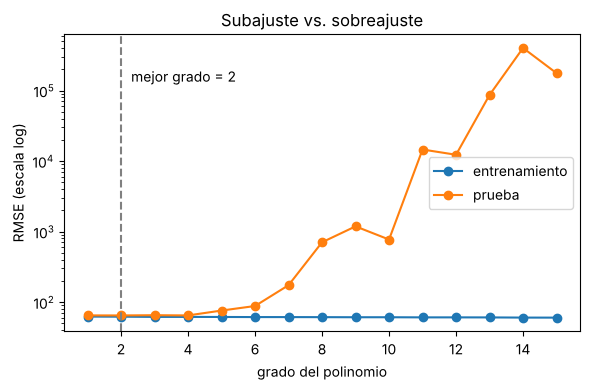

Mejor grado según prueba: 2 (RMSE = 64.66)
Grado 15: RMSE entrenamiento = 60.21 | prueba = 176243.58


In [6]:
plt.plot(res.index, res['RMSE_entrenamiento'], 'o-', label='entrenamiento')
plt.plot(res.index, res['RMSE_prueba'], 'o-', label='prueba')
plt.yscale('log')   # el error de prueba crece muchísimo: escala logarítmica

mejor = res['RMSE_prueba'].idxmin()
plt.axvline(mejor, ls='--', c='gray')
plt.text(mejor + 0.3, res['RMSE_prueba'].max() / 3, f'mejor grado = {mejor}')

plt.xlabel('grado del polinomio'); plt.ylabel('RMSE (escala log)')
plt.title('Subajuste vs. sobreajuste')
plt.legend(); plt.tight_layout(); plt.show()

print(f'Mejor grado según prueba: {mejor} (RMSE = {res.loc[mejor, "RMSE_prueba"]:.2f})')
print(f'Grado 15: RMSE entrenamiento = {res.loc[15, "RMSE_entrenamiento"]:.2f} '
      f'| prueba = {res.loc[15, "RMSE_prueba"]:.2f}')

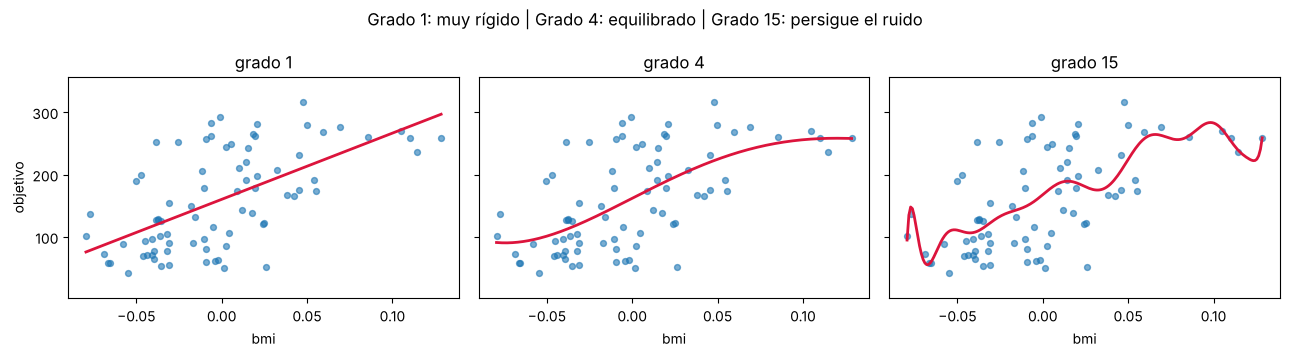

In [7]:
# ¿Cómo se ve cada ajuste? Comparamos tres grados sobre los mismos datos
rejilla = np.linspace(Xb_train['bmi'].min(), Xb_train['bmi'].max(), 200).reshape(-1, 1)
rejilla_df = pd.DataFrame(rejilla, columns=['bmi'])

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, d in zip(axes, [1, 4, 15]):
    modelo = make_pipeline(MinMaxScaler((-1, 1)),
                           PolynomialFeatures(d),
                           LinearRegression()).fit(Xb_train, yb_train)
    ax.scatter(Xb_train['bmi'], yb_train, s=18, alpha=0.6, label='datos')
    ax.plot(rejilla_df['bmi'], modelo.predict(rejilla_df), c='crimson', lw=2)
    ax.set_title(f'grado {d}')
    ax.set_xlabel('bmi')
axes[0].set_ylabel('objetivo')
axes[0].set_ylim(yb_train.min() - 40, yb_train.max() + 40)
plt.suptitle('Grado 1: muy rígido | Grado 4: equilibrado | Grado 15: persigue el ruido')
plt.tight_layout(); plt.show()

**Lectura.**

- **Grados bajos (1–2):** error alto en los dos conjuntos → **subajuste**, el modelo es
  demasiado rígido para los datos.
- **Grado intermedio:** el error de prueba toca su mínimo → es el mejor equilibrio.
- **Grados altos:** el error de entrenamiento sigue bajando lentamente, mientras el de
  prueba se dispara en órdenes de magnitud → **sobreajuste**: el modelo memoriza el
  ruido de la muestra y falla con datos nuevos.

La señal práctica de sobreajuste es justo esa **brecha creciente** entre las dos curvas,
y en el último gráfico se ve por qué: la curva de grado 15 se retuerce para pasar cerca
de cada punto.

## Paso 4 – Validación cruzada: comparar 3 modelos

Una sola partición puede ser "afortunada". Con **K-Fold (k = 5)** dividimos el
entrenamiento en 5 partes, entrenamos 5 veces y promediamos: la estimación es
mucho más estable.

Comparamos tres modelos lineales:

| Modelo | Idea |
|---|---|
| `LinearRegression` | sin regularización |
| `Ridge` | penaliza coeficientes grandes (L2) |
| `Lasso` | además puede dejar coeficientes en 0 (L1) |

Cada modelo va dentro de un `Pipeline` con `StandardScaler`, para que el escalado
se calcule **dentro de cada fold** y no haya fuga de datos.

In [8]:
modelos = {
    'LinearRegression': LinearRegression(),
    'Ridge (alpha=1)':  Ridge(alpha=1.0),
    'Lasso (alpha=0.1)': Lasso(alpha=0.1, max_iter=10000),
}

cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
resumen = []

for nombre, m in modelos.items():
    pipe = Pipeline([('scaler', StandardScaler()), ('modelo', m)])
    rmse = -cross_val_score(pipe, X_train, y_train, cv=cv,
                            scoring='neg_root_mean_squared_error')
    r2 = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='r2')
    resumen.append({'modelo': nombre,
                    'RMSE_medio': rmse.mean(), 'RMSE_desv': rmse.std(),
                    'R2_medio': r2.mean()})

cv_tabla = pd.DataFrame(resumen).set_index('modelo').round(3)
cv_tabla

,RMSE_medio,RMSE_desv,R2_medio
modelo,,,
LinearRegression,55.395,2.361,0.480
Ridge (alpha=1),55.374,2.373,0.481
Lasso (alpha=0.1),55.354,2.356,0.481


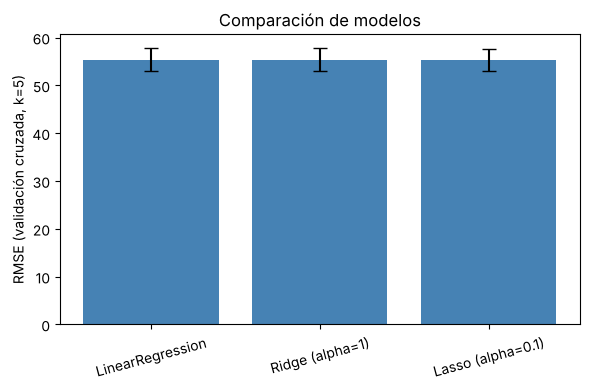

In [9]:
plt.bar(cv_tabla.index, cv_tabla['RMSE_medio'],
        yerr=cv_tabla['RMSE_desv'], capsize=5, color='steelblue')
plt.ylabel('RMSE (validación cruzada, k=5)')
plt.title('Comparación de modelos')
plt.xticks(rotation=15); plt.tight_layout(); plt.show()

**Lectura.** Los tres modelos quedan muy parecidos, y las barras de error se
solapan: con estos datos la regularización no cambia mucho el desempeño. Lo
importante del paso es el **método**: comparar con validación cruzada y mirar
también la desviación, no solo el promedio.

## Paso 5 – `GridSearchCV` y `RandomizedSearchCV`

Ahora buscamos el mejor **hiperparámetro** (`alpha`) de forma automática.

- **`GridSearchCV`**: prueba *todas* las combinaciones de una lista. Exhaustivo pero costoso.
- **`RandomizedSearchCV`**: prueba *n* combinaciones al azar. Más rápido cuando el espacio es grande.

Las dos búsquedas usan validación cruzada internamente y **solo** los datos de entrenamiento.

In [10]:
# --- GridSearchCV sobre Ridge ---
pipe_ridge = Pipeline([('scaler', StandardScaler()), ('modelo', Ridge())])
malla = {'modelo__alpha': [0.001, 0.01, 0.1, 1, 10, 100, 1000]}

grid = GridSearchCV(pipe_ridge, malla, cv=cv,
                    scoring='neg_root_mean_squared_error')
grid.fit(X_train, y_train)

print('GridSearchCV')
print('  mejor alpha :', grid.best_params_['modelo__alpha'])
print(f'  RMSE (CV)   : {-grid.best_score_:.2f}')

pd.DataFrame(grid.cv_results_)[['param_modelo__alpha', 'mean_test_score']] \
  .assign(RMSE=lambda d: -d['mean_test_score']) \
  .drop(columns='mean_test_score').round(3)

GridSearchCV
  mejor alpha : 1
  RMSE (CV)   : 55.37


,param_modelo__alpha,RMSE
0,0.001,55.395
1,0.010,55.394
2,0.100,55.389
3,1.000,55.374
4,10.000,55.435
5,100.000,56.001
6,1000.000,64.386


In [11]:
# --- RandomizedSearchCV sobre Lasso ---
pipe_lasso = Pipeline([('scaler', StandardScaler()), ('modelo', Lasso(max_iter=10000))])
distrib = {'modelo__alpha': np.logspace(-3, 1, 100)}

rand = RandomizedSearchCV(pipe_lasso, distrib, n_iter=20, cv=cv,
                          scoring='neg_root_mean_squared_error',
                          random_state=SEED)
rand.fit(X_train, y_train)

print('RandomizedSearchCV')
print(f'  mejor alpha : {rand.best_params_["modelo__alpha"]:.4f}')
print(f'  RMSE (CV)   : {-rand.best_score_:.2f}')
print(f'  combinaciones probadas: 20 de 100 posibles')

RandomizedSearchCV
  mejor alpha : 0.1385
  RMSE (CV)   : 55.35
  combinaciones probadas: 20 de 100 posibles


Variables descartadas por Lasso: ['s3']


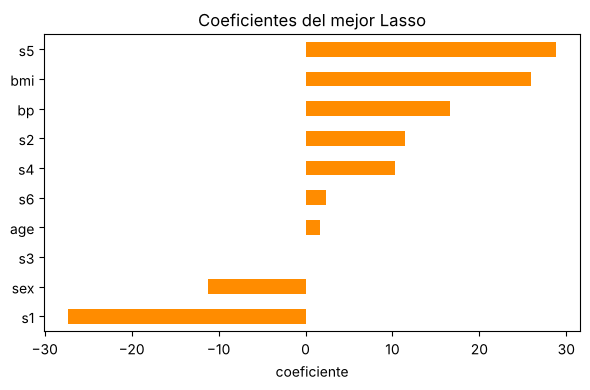

In [12]:
# Coeficientes que el Lasso dejó en cero (selección de variables)
coef = pd.Series(rand.best_estimator_['modelo'].coef_, index=X.columns)
print('Variables descartadas por Lasso:', list(coef[coef == 0].index) or 'ninguna')
coef.sort_values().plot.barh(color='darkorange')
plt.title('Coeficientes del mejor Lasso'); plt.xlabel('coeficiente')
plt.tight_layout(); plt.show()

In [13]:
# --- Evaluación final: el conjunto de prueba se usa UNA sola vez ---
final = grid.best_estimator_   # el mejor Ridge encontrado

comparacion = pd.DataFrame({
    'modelo base (lineal)': metricas(lr, X_test, y_test),
    'mejor Ridge (Grid)':   metricas(final, X_test, y_test),
}).round(3)
comparacion

,modelo base (lineal),mejor Ridge (Grid)
MAE,42.794,42.812
RMSE,53.853,53.777
R2,0.453,0.454


**Lectura.** `GridSearchCV` recorre la malla completa y `RandomizedSearchCV` llega a un
resultado parecido probando solo una fracción de los valores: esa es su ventaja cuando
hay muchos hiperparámetros. El Lasso además pone en cero algunos coeficientes, o sea
que hace **selección de variables** por sí solo.

El modelo ajustado mejora poco al base, lo cual es coherente con el Paso 4: el límite
aquí no es el hiperparámetro, es que la relación no es del todo lineal.

## Paso 6 – Clasificación: matriz de confusión, F1 y AUC

Cambiamos de problema: dataset **breast_cancer**, donde hay que predecir si un tumor
es benigno (1) o maligno (0).

Métricas de clasificación:

- **Matriz de confusión**: aciertos y errores por clase.
- **Precisión**: de lo que predije positivo, ¿cuánto lo era?
- **Recall**: de los positivos reales, ¿cuántos detecté?
- **F1**: promedio armónico de las dos; útil con clases desbalanceadas.
- **AUC**: qué tan bien el modelo *ordena* los casos, sin depender del umbral.

In [14]:
Xc, yc = load_breast_cancer(return_X_y=True, as_frame=True)

Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    Xc, yc, test_size=0.20, stratify=yc, random_state=SEED)

clf = Pipeline([('scaler', StandardScaler()),
                ('modelo', LogisticRegression(max_iter=1000))]).fit(Xc_train, yc_train)

pred  = clf.predict(Xc_test)
proba = clf.predict_proba(Xc_test)[:, 1]

print(f'F1  = {f1_score(yc_test, pred):.3f}')
print(f'AUC = {roc_auc_score(yc_test, proba):.3f}')
print()
print(classification_report(yc_test, pred,
      target_names=['maligno (0)', 'benigno (1)'], digits=3))

F1  = 0.986
AUC = 0.995

              precision    recall  f1-score   support

 maligno (0)      0.976     0.976     0.976        42
 benigno (1)      0.986     0.986     0.986        72

    accuracy                          0.982       114
   macro avg      0.981     0.981     0.981       114
weighted avg      0.982     0.982     0.982       114



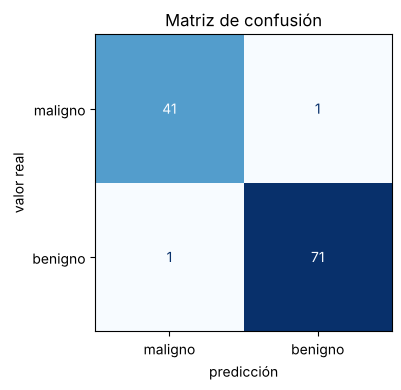

In [15]:
ConfusionMatrixDisplay.from_estimator(
    clf, Xc_test, yc_test,
    display_labels=['maligno', 'benigno'], cmap='Blues', colorbar=False)
plt.xlabel('predicción'); plt.ylabel('valor real')
plt.title('Matriz de confusión'); plt.tight_layout(); plt.show()

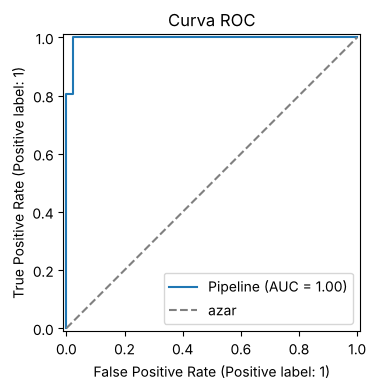

In [16]:
RocCurveDisplay.from_estimator(clf, Xc_test, yc_test)
plt.plot([0, 1], [0, 1], '--', c='gray', label='azar')
plt.title('Curva ROC'); plt.legend(); plt.tight_layout(); plt.show()

### Efecto del umbral de decisión

Por defecto se clasifica como positivo si la probabilidad ≥ 0.5. Al mover ese umbral
se cambia el balance entre precisión y recall. En un diagnóstico médico interesa un
**recall alto** en la clase grave, aunque cueste algunos falsos positivos.

In [17]:
from sklearn.metrics import precision_score, recall_score

filas = []
for t in (0.3, 0.5, 0.7, 0.9):
    p = (proba >= t).astype(int)
    filas.append({'umbral': t,
                  'precisión': precision_score(yc_test, p),
                  'recall':    recall_score(yc_test, p),
                  'F1':        f1_score(yc_test, p)})

pd.DataFrame(filas).set_index('umbral').round(3)

,precisión,recall,F1
umbral,,,
0.3,0.973,1.000,0.986
0.5,0.986,0.986,0.986
0.7,0.985,0.931,0.957
0.9,0.984,0.847,0.910


**Lectura.** El clasificador funciona muy bien (F1 y AUC cercanos a 1) y la matriz de
confusión muestra pocos errores. Al bajar el umbral sube el recall y baja la precisión;
al subirlo pasa lo contrario. El AUC no cambia con el umbral, porque mide la capacidad
de ordenamiento del modelo, no una decisión concreta.

## Conclusiones

1. **Partición.** Entrenamiento y prueba se separan al inicio y el conjunto de prueba se
   usa una sola vez, al final.
2. **Métricas.** MAE y RMSE dicen *cuánto* se equivoca el modelo; R², *qué parte* de la
   variabilidad explica. Siempre se reportan en entrenamiento **y** en prueba.
3. **Sobreajuste.** Con polinomios de grado 1 a 15 se ve el patrón clásico: el error de
   entrenamiento baja sin parar mientras el de prueba vuelve a subir.
4. **Validación cruzada.** Con k = 5 la comparación entre modelos es más confiable que
   con una sola partición, y la desviación indica qué tan estable es el resultado.
5. **Búsqueda de hiperparámetros.** `GridSearchCV` es exhaustivo; `RandomizedSearchCV`
   consigue resultados similares con menos pruebas. Las dos van dentro de un `Pipeline`
   para evitar fuga de datos.
6. **Clasificación.** La exactitud sola no alcanza: la matriz de confusión muestra *qué*
   tipo de error se comete, F1 equilibra precisión y recall, y el AUC resume el desempeño
   para todos los umbrales.

---

### Reto – Proyecto del curso (base de tiendas)

1. Carga tu base preprocesada y define la variable objetivo.
2. Haz la partición entrenamiento/prueba y evalúa un modelo base con validación cruzada.
3. Ajusta hiperparámetros con `GridSearchCV` dentro de un `Pipeline` (evita la fuga de datos).
4. Reporta MAE, RMSE y R² en prueba y justifica la elección del modelo.